# 04 Photo Prediction

This notebook is a small demo for using the trained sign-language classifier on a self-made hand photo.

Important limitation: the model was trained on the provided dataset images. A real phone or webcam photo can have a different background, lighting, scale and hand position. Therefore this notebook is useful as a demo, but the prediction is not guaranteed to be correct.

Recommended setup for the photo:
- Use a plain, high-contrast background.
- Put the hand/sign in the center of the image.
- Make the hand fill most of the image.
- Avoid strong shadows.
- Use the same sign orientation as in the training data.

In [22]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\tobi\Documents\Machine-Learning\ps\project_submission


In [23]:
import io

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

from src.dataset import load_labels, make_label_mapping, make_transforms
from src.models import SimpleMLP, ImprovedMLP
from src.train_utils import get_device

## Load class labels

The saved PyTorch model only stores the learned weights. To convert output indices back to letters/classes, we recreate the same label mapping from `labels.csv` that was used during training.

In [24]:
DATA_ROOT = PROJECT_ROOT / "sign_lang_train" / "sign_lang_train"

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_ROOT}\n"
        "Please place the dataset there or change DATA_ROOT."
    )

df = load_labels(DATA_ROOT)
label_to_idx, idx_to_label = make_label_mapping(df["label"])

print("Number of classes:", len(label_to_idx))
print("Classes:", list(label_to_idx.keys()))

Number of classes: 36
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


## Load the trained model

By default we use the baseline MLP because it performed better in the final evaluation notebook. You can switch to the improved model by changing `MODEL_NAME` to `"improved"`.

In [25]:
IMAGE_SIZE = 64
MODEL_NAME = "improved"  # "baseline" or "improved"

device = get_device()

if MODEL_NAME == "baseline":
    model_path = PROJECT_ROOT / "saved_models" / "mlp_baseline_8epochs.pt"
    model = SimpleMLP(
        input_size=IMAGE_SIZE * IMAGE_SIZE,
        hidden_size=512,
        num_classes=len(label_to_idx),
    ).to(device)
elif MODEL_NAME == "improved":
    model_path = PROJECT_ROOT / "saved_models" / "mlp_improved.pt"
    model = ImprovedMLP(
        input_size=IMAGE_SIZE * IMAGE_SIZE,
        hidden_size=512,
        num_classes=len(label_to_idx),
        dropout=0.3,
    ).to(device)
else:
    raise ValueError("MODEL_NAME must be 'baseline' or 'improved'.")

if not model_path.exists():
    raise FileNotFoundError(f"Model file not found: {model_path}")

model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print("Loaded model:", MODEL_NAME)
print("Model path:", model_path)
print("Device:", device)

Loaded model: improved
Model path: c:\Users\tobi\Documents\Machine-Learning\ps\project_submission\saved_models\mlp_improved.pt
Device: cpu


## Prediction helper functions

The function below uses the same preprocessing as the training/evaluation notebooks: grayscale, resize to `64 x 64`, tensor conversion and normalization.

For real photos, `center_crop=True` is often helpful because it removes irrelevant borders. If your photo is already tightly cropped around the hand, you can set it to `False`.

In [26]:
eval_transform = make_transforms(image_size=IMAGE_SIZE, augment=False)

def center_crop_square(image: Image.Image) -> Image.Image:
    """Crop the image to the largest centered square."""
    width, height = image.size
    side = min(width, height)
    left = (width - side) // 2
    top = (height - side) // 2
    return image.crop((left, top, left + side, top + side))


def prepare_image(image: Image.Image, center_crop: bool = True, invert: bool = False) -> torch.Tensor:
    """Convert a PIL image into the tensor format expected by the MLP."""
    image = image.convert("RGB")

    if center_crop:
        image = center_crop_square(image)

    if invert:
        image = ImageOps.invert(image)

    tensor = eval_transform(image).unsqueeze(0)  # shape: [1, 1, 64, 64]
    return tensor


def predict_pil_image(
    image: Image.Image,
    top_k: int = 5,
    center_crop: bool = True,
    invert: bool = False,
):
    """Predict the class of a PIL image and return the top-k probabilities."""
    x = prepare_image(image, center_crop=center_crop, invert=invert).to(device)

    with torch.no_grad():
        logits = model(x)
        probabilities = F.softmax(logits, dim=1).squeeze(0).cpu()

    top_probs, top_indices = torch.topk(probabilities, k=min(top_k, len(probabilities)))
    predictions = [
        {
            "rank": rank + 1,
            "label": idx_to_label[int(index)],
            "probability": float(prob),
        }
        for rank, (prob, index) in enumerate(zip(top_probs, top_indices))
    ]
    return predictions


def show_prediction(
    image: Image.Image,
    top_k: int = 5,
    center_crop: bool = True,
    invert: bool = False,
):
    """Display the image and print the top-k prediction table."""
    predictions = predict_pil_image(
        image,
        top_k=top_k,
        center_crop=center_crop,
        invert=invert,
    )

    display_image = center_crop_square(image) if center_crop else image

    plt.figure(figsize=(4, 4))
    plt.imshow(display_image)
    plt.axis("off")
    plt.title(f"Predicted class: {predictions[0]['label']}")
    plt.show()

    for item in predictions:
        print(f"{item['rank']}. {item['label']}: {item['probability']:.3f}")

    return predictions

## Extra demo: choose a label and classify a random dataset image

Use this cell to type a sign label, randomly select one image with that ground-truth label from the dataset, and let the trained model classify it. This is useful to quickly check whether the loaded model works on known dataset images before trying new camera photos.


In [27]:
import random

def normalize_requested_label(requested_label: str) -> str:
    """Normalize user input and check whether the label exists in the dataset."""
    requested_label = str(requested_label).strip()

    candidates = [
        requested_label,
        requested_label.upper(),
        requested_label.lower(),
    ]

    for candidate in candidates:
        if candidate in label_to_idx:
            return candidate

    available = ", ".join(label_to_idx.keys())
    raise ValueError(
        f"Unknown label: {requested_label!r}. Available labels are: {available}"
    )


def predict_random_dataset_image_for_label(
    requested_label: str | None = None,
    top_k: int = 5,
    seed: int | None = None,
):
    """
    Ask for a label, randomly choose one matching dataset image,
    and classify it with the currently loaded model.
    """
    if requested_label is None:
        requested_label = input("Enter a sign label, for example A, B, C, 0, 1: ")

    label = normalize_requested_label(requested_label)
    matching_rows = df[df["label"].astype(str) == label]

    if matching_rows.empty:
        raise ValueError(f"No dataset images found for label {label!r}.")

    if seed is None:
        row = matching_rows.sample(n=1).iloc[0]
    else:
        row = matching_rows.sample(n=1, random_state=seed).iloc[0]

    image_path = Path(row["image_path"])
    image = Image.open(image_path).convert("RGB")

    print(f"Requested label: {label}")
    print(f"Random dataset file: {image_path.name}")
    print(f"Full path: {image_path}")

    predictions = show_prediction(
        image,
        top_k=top_k,
        center_crop=False,
        invert=False,
    )

    predicted_label = predictions[0]["label"]
    print(f"Ground truth label: {label}")
    print(f"Predicted label: {predicted_label}")
    print("Correct prediction:", predicted_label == label)

    return image, predictions



Requested label: a
Random dataset file: AAGCPLLMPMRDZFPD.jpg
Full path: c:\Users\tobi\Documents\Machine-Learning\ps\project_submission\sign_lang_train\sign_lang_train\AAGCPLLMPMRDZFPD.jpg


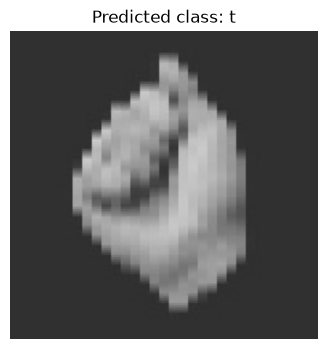

1. t: 0.201
2. a: 0.178
3. s: 0.165
4. y: 0.121
5. e: 0.108
Ground truth label: a
Predicted label: t
Correct prediction: False


In [39]:
random_dataset_image, random_dataset_predictions = predict_random_dataset_image_for_label(
    requested_label="a",
    top_k=5,
    seed=None,
)

## Option A: take a photo with the webcam

This cell starts the browser camera. Click **Take photo**, then run the next cell to save the image inside the project.

The notebook saves two files:

- `demo_images/camera_raw.png`: original camera capture
- `demo_images/camera_processed.png`: cropped/resized version used by the model

If the camera is blocked by JupyterHub or the browser, use the file-path or upload option below.


In [29]:
from IPython.display import HTML, display

camera_html = """
<div style="border: 1px solid #ddd; padding: 12px; max-width: 420px;">
    <video id="video" width="360" height="270" autoplay playsinline style="background: #111;"></video>
    <br><br>
    <button id="snap" style="padding: 6px 12px;">Take photo</button>
    <canvas id="canvas" width="360" height="270" style="display:none;"></canvas>
    <p id="status">Starting camera...</p>
</div>

<script>
const video = document.getElementById('video');
const canvas = document.getElementById('canvas');
const snap = document.getElementById('snap');
const statusText = document.getElementById('status');

function sendToKernel(variableName, value) {
    const code = variableName + " = " + JSON.stringify(value);

    // Classic Notebook
    if (typeof Jupyter !== "undefined" && Jupyter.notebook && Jupyter.notebook.kernel) {
        Jupyter.notebook.kernel.execute(code);
        return true;
    }

    // Some older notebook frontends
    if (typeof IPython !== "undefined" && IPython.notebook && IPython.notebook.kernel) {
        IPython.notebook.kernel.execute(code);
        return true;
    }

    return false;
}

if (!navigator.mediaDevices || !navigator.mediaDevices.getUserMedia) {
    statusText.innerText = "Camera API is not available in this browser. Use the upload option below.";
} else {
    navigator.mediaDevices.getUserMedia({ video: true, audio: false })
        .then(stream => {
            video.srcObject = stream;
            statusText.innerText = "Camera ready. Hold your hand sign in front of the camera and click Take photo.";
        })
        .catch(err => {
            statusText.innerText = "Camera error: " + err + ". Use the upload option below.";
        });
}

snap.onclick = () => {
    const context = canvas.getContext('2d');
    context.drawImage(video, 0, 0, canvas.width, canvas.height);
    const dataURL = canvas.toDataURL('image/png');
    const ok = sendToKernel("camera_image_data", dataURL);

    if (ok) {
        statusText.innerText = "Photo captured. Now run the next cell to save and classify it.";
    } else {
        statusText.innerText = "Photo captured, but this Jupyter frontend could not send it to Python. Use the upload option below.";
    }
};
</script>
"""

display(HTML(camera_html))


In [30]:
from pathlib import Path
from io import BytesIO
import base64

CAMERA_DIR = PROJECT_ROOT / "demo_images"
CAMERA_RAW_PATH = CAMERA_DIR / "camera_raw.png"
CAMERA_PROCESSED_PATH = CAMERA_DIR / "camera_processed.png"


def save_camera_capture(data_url: str, invert: bool = False):
    """Save the camera image and the preprocessed model input image."""
    if not isinstance(data_url, str) or "," not in data_url:
        raise ValueError("No valid camera image found. Run the camera cell and click 'Take photo' first.")

    CAMERA_DIR.mkdir(exist_ok=True)

    _, encoded = data_url.split(",", 1)
    image_bytes = base64.b64decode(encoded)

    raw_image = Image.open(BytesIO(image_bytes)).convert("RGB")
    raw_image.save(CAMERA_RAW_PATH)

    processed_image = center_crop_square(raw_image).convert("RGB")
    if invert:
        processed_image = ImageOps.invert(processed_image)
    processed_image = processed_image.convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
    processed_image.save(CAMERA_PROCESSED_PATH)

    print(f"Saved raw camera image to: {CAMERA_RAW_PATH}")
    print(f"Saved processed model image to: {CAMERA_PROCESSED_PATH}")
    print(f"Processed image size: {processed_image.size}")

    display(processed_image)
    return raw_image, processed_image


if "camera_image_data" not in globals():
    print("No camera photo found yet. Run the camera cell above and click 'Take photo' first.")
else:
    raw_camera_image, processed_camera_image = save_camera_capture(camera_image_data, invert=False)


No camera photo found yet. Run the camera cell above and click 'Take photo' first.


In [31]:
if CAMERA_RAW_PATH.exists():
    camera_image = Image.open(CAMERA_RAW_PATH)
    camera_predictions = show_prediction(camera_image, top_k=5, center_crop=True, invert=False)
else:
    print("No saved camera image found. Run the camera capture and save cells first.")


No saved camera image found. Run the camera capture and save cells first.


## Option B: take a photo with OpenCV in VS Code

Use this option when the browser camera above is blocked. This is often the better method when the notebook runs locally in VS Code.

The cell opens a separate camera window. Press **SPACE** to save a photo, or **ESC** to cancel.

The notebook saves two files:

- `demo_images/opencv_camera_raw.png`: original camera capture
- `demo_images/opencv_camera_processed.png`: cropped/resized version used by the model

If camera index `0` does not work, try `1` or `2`.


In [32]:
from pathlib import Path

OPENCV_CAMERA_INDEX = 0  # try 1 or 2 if your default camera is not found
OPENCV_RAW_PATH = PROJECT_ROOT / "demo_images" / "opencv_camera_raw.png"
OPENCV_PROCESSED_PATH = PROJECT_ROOT / "demo_images" / "opencv_camera_processed.png"

def capture_photo_with_opencv(camera_index: int = OPENCV_CAMERA_INDEX, invert: bool = False):
    """Capture one photo via OpenCV, save it, preprocess it, and display the processed image."""
    try:
        import cv2
    except ImportError as exc:
        raise ImportError(
            "OpenCV is not installed. Install it with: pip install opencv-python"
        ) from exc

    OPENCV_RAW_PATH.parent.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open camera index {camera_index}. Try OPENCV_CAMERA_INDEX = 1 or 2, "
            "or check the camera permissions in Windows/VS Code."
        )

    print("Camera window opened. Press SPACE to take a photo, or ESC to cancel.")
    captured = False

    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                raise RuntimeError("Could not read a frame from the camera.")

            cv2.imshow("Camera - press SPACE to capture, ESC to cancel", frame)
            key = cv2.waitKey(1) & 0xFF

            if key == 27:  # ESC
                print("Cancelled.")
                break

            if key == 32:  # SPACE
                cv2.imwrite(str(OPENCV_RAW_PATH), frame)
                captured = True
                print(f"Saved raw image to: {OPENCV_RAW_PATH}")
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()

    if not captured:
        return None

    raw_image = Image.open(OPENCV_RAW_PATH)
    processed_tensor = prepare_image(raw_image, center_crop=True, invert=invert)

    processed_display = raw_image.convert("L")
    processed_display = center_crop_square(processed_display)
    if invert:
        processed_display = ImageOps.invert(processed_display)
    processed_display = processed_display.resize((IMAGE_SIZE, IMAGE_SIZE))
    processed_display.save(OPENCV_PROCESSED_PATH)

    print(f"Saved processed image to: {OPENCV_PROCESSED_PATH}")
    display(processed_display)
    return raw_image

# Run this line to take a photo in VS Code/local Jupyter:
opencv_image = capture_photo_with_opencv(camera_index=OPENCV_CAMERA_INDEX, invert=False)


Camera window opened. Press SPACE to take a photo, or ESC to cancel.
Cancelled.


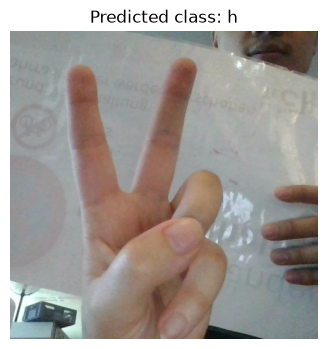

1. h: 0.415
2. p: 0.364
3. q: 0.104
4. g: 0.038
5. 4: 0.021


In [33]:
if OPENCV_RAW_PATH.exists():
    opencv_image = Image.open(OPENCV_RAW_PATH)
    opencv_predictions = show_prediction(opencv_image, top_k=5, center_crop=True, invert=False)
else:
    print("No OpenCV camera image found. Run the OpenCV capture cell first.")


## Option C: classify an image file

Take a photo of your hand/sign, copy it into the project folder, and set `IMAGE_PATH` to that file. This is the most reliable option in JupyterHub.

In [34]:
IMAGE_PATH = PROJECT_ROOT / "example_hand_photo.jpg"

if IMAGE_PATH.exists():
    image = Image.open(IMAGE_PATH)
    predictions = show_prediction(image, top_k=5, center_crop=True, invert=False)
else:
    print(f"No image found at: {IMAGE_PATH}")
    print("Take or upload a photo and set IMAGE_PATH to the correct filename.")

No image found at: c:\Users\tobi\Documents\Machine-Learning\ps\project_submission\example_hand_photo.jpg
Take or upload a photo and set IMAGE_PATH to the correct filename.


## Option D: upload a photo inside the notebook

Use this cell when you do not want to edit `IMAGE_PATH`. Click the upload button, select a photo, and then click **Classify uploaded image**.

In [35]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    uploader = widgets.FileUpload(
        accept="image/*",
        multiple=False,
        description="Upload photo",
    )
    classify_button = widgets.Button(
        description="Classify uploaded image",
        button_style="primary",
    )
    output = widgets.Output()

    def _get_uploaded_bytes(file_upload_widget):
        value = file_upload_widget.value

        # ipywidgets 7 returns a dict, ipywidgets 8 returns a tuple/list of dicts.
        if isinstance(value, dict):
            if len(value) == 0:
                return None
            first_file = next(iter(value.values()))
            return first_file["content"]

        if isinstance(value, (tuple, list)):
            if len(value) == 0:
                return None
            return value[0]["content"]

        return None

    def on_classify_clicked(_):
        with output:
            clear_output(wait=True)
            image_bytes = _get_uploaded_bytes(uploader)
            if image_bytes is None:
                print("Please upload an image first.")
                return

            image = Image.open(io.BytesIO(image_bytes))
            show_prediction(image, top_k=5, center_crop=True, invert=False)

    classify_button.on_click(on_classify_clicked)
    display(widgets.VBox([uploader, classify_button, output]))

except ImportError:
    print("ipywidgets is not installed. Use Option A instead, or install ipywidgets.")

ipywidgets is not installed. Use Option A instead, or install ipywidgets.


## Interpretation

The output probabilities are the model's confidence values after the softmax function. A high value only means that the model is confident under its learned training distribution. For real photos, wrong predictions are expected if the background, lighting, hand scale or sign orientation differs strongly from the training images.